# Experiments v2: sanity checks, logged runs, curves

Run order: 1) setup, 2) sanity checks (once, and after every major code change), 3) run an experiment,
4) look at the log and curves. The test set is not touched here. Use the last cell only for the final
evaluation of chosen models.

Before first use: copy the files from the `src/` folder of this package into
`.../Project_deep/src/` on the shared Drive (they replace `losses.py`, `trainer.py` and `models.py`
and add `sanity_checks.py`, `experiment.py` and `experiment_log.py`). `dataset.py` stays as it is.

In [2]:
from google.colab import drive

drive.mount("/content/drive")

import sys, json, torch

PROJECT_ROOT = "/content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep"
if PROJECT_ROOT not in sys.path:
    sys.path.append(PROJECT_ROOT)

from src.dataset import build_dataloaders
from src.models import get_resnet18
from src.losses import get_loss_function
from src import sanity_checks as sc
from src.experiment import run_experiment, final_test_eval
from src.experiment_log import summarise

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# Everything that defines an experiment is here. Change ONE factor at a time.
CONFIG = {
    "experiment_id": "E2",  # E0ga = E0g2 protocol plus cosine lr decay
    "seeds": [0, 42, 123],
    "epochs": 10,
    "batch_size": 32,
    "lr": 1e-4,
    "img_size": 224,
    "num_classes": 15,
    "freeze_backbone": False,  # True = train only the new head
    "dropout": 0.0,
    "lr_schedule": "cosine",  # 'constant' (as in E0) or 'cosine' (decays to 0 over the epochs)
}

Mounted at /content/drive
device: cuda


In [ ]:
import os

print("cell 1 active (CONFIG exists):", "CONFIG" in globals())
print(
    "cell 2 active (data exists):",
    all(
        os.path.isdir(f"/content/data/{s}") and len(os.listdir(f"/content/data/{s}")) == 15
        for s in ("train", "val", "test")
    ),
)

cell 1 active (CONFIG exists): True
cell 2 active (data exists): False


## 1. Sanity checks (Lab 6, Part A)
The output of the last cell is the table for Part A of the iteration log.

Data ikke fundet lokalt. Udpakker plant_data.zip til /content/data/ ...
Data udpakning færdig!
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 156MB/s]


Focal loss test: CE 3.2320, focal gamma=0 3.2320, focal gamma=2 2.9603. Passed: True
Class weight order test: largest weight is for 'Potato___healthy', smallest class is 'Potato___healthy'. Passed: True
train: mean per channel [-0.335, -0.107, -0.214], std per channel [0.922, 0.872, 0.948], min -2.12, max 2.64
  val: mean per channel [-0.122, 0.075, 0.021], std per channel [0.813, 0.733, 0.887], min -2.12, max 2.64
 test: mean per channel [-0.108, 0.095, 0.027], std per channel [0.806, 0.72, 0.903], min -2.12, max 2.64
A. data statistics sensible: True, splits consistent with each other: False


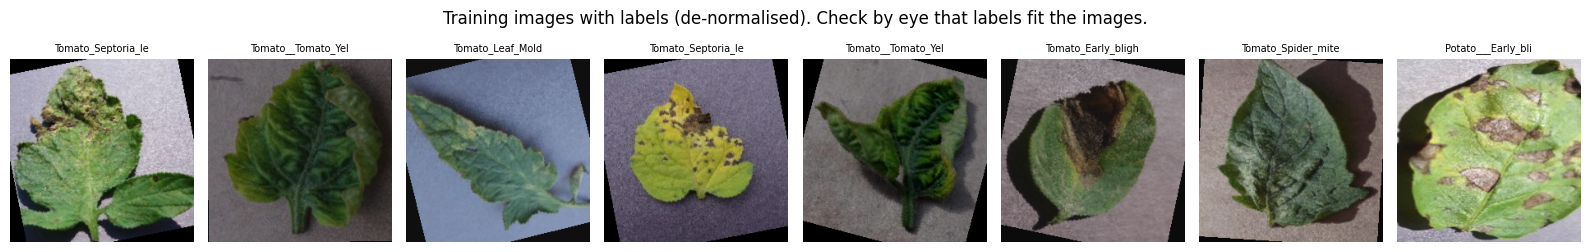

B. identical class lists and order in all splits: True
   overlap train/val: same path 0, same file name 0, same content 0
   overlap train/test: same path 0, same file name 0, same content 0
   overlap val/test: same path 0, same file name 0, same content 0
   split sizes: train 16456 (79.8%), val 2100 (10.2%), test 2077 (10.1%)
   class                                            train     val    test  all
   Pepper__bell___Bacterial_spot                      797     100     100  997
   Pepper__bell___healthy                            1182     148     148  1478
   Potato___Early_blight                              800     100     100  1000
   Potato___Late_blight                               800     100     100  1000
   Potato___healthy                                   120      16      16  152
   Tomato_Bacterial_spot                             1700     215     212  2127
   Tomato_Early_blight                                800     100     100  1000
   Tomato_Late_blight          

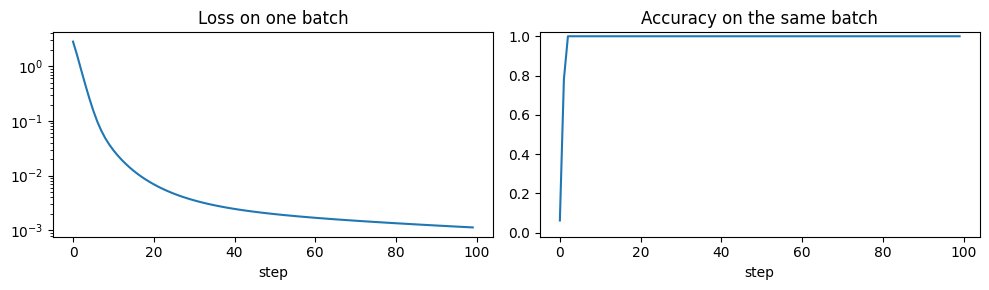


| Check | Result | Pass? |
|---|---|:---:|
| A. Data statistics and images | see output above | NO |
| B. Split overlap and class order | see output above | yes |
| C. Initial loss (2.837 vs ln(C) = 2.708) | see output above | yes |
| D. Overfit one batch (final loss 0.0011, acc 1.00) | see output above | yes |


{'A': False, 'B': True, 'C': True, 'D': True}

In [ ]:
train_dir, val_dir, test_dir = "/content/data/train", "/content/data/val", "/content/data/test"
train_loader, val_loader, test_loader, class_names = build_dataloaders(train_dir, val_dir, test_dir, CONFIG)
model = get_resnet18(CONFIG["num_classes"], CONFIG["freeze_backbone"], CONFIG["dropout"]).to(device)
criterion = get_loss_function(CONFIG["experiment_id"], train_loader, device=device)

# Unit-style tests
sc.test_focal_equals_ce()
sc.test_class_weight_order(train_loader, class_names)

# Checks A to D
sc.run_all_checks(
    loaders={"train": train_loader, "val": val_loader, "test": test_loader},
    datasets={"train": train_loader.dataset, "val": val_loader.dataset, "test": test_loader.dataset},
    model=model,
    criterion=criterion,
    device=device,
    class_names=class_names,
)

In [ ]:
# Delete local data folder after an interrupted data copy (one-off, do not keep).
import shutil

shutil.rmtree("/content/data", ignore_errors=True)

In [ ]:
# Check that Drive is mounted and the project folder is readable (one-off, do not keep).
import os

print(os.listdir(PROJECT_ROOT))

['Exploring_deep', 'plant_data.zip', 'data_check.ipynb', 'Project proposal.gdoc', 'Scripts', 'DONE_split_script.ipynb', 'data_split_loader.ipynb', 'src', 'dummy_model.ipynb', 'Project notes.gdoc', 'results_E0.json', 'Appendix.gdoc', 'Rapport.gdoc', 'splits_v1.json', 'runs', 'checkpoints', 'To do .gdoc', 'splits_v2_dedup.json', 'split_groups_v3.csv', 'splits_v3_b64.json', 'split_groups_v3_b64.csv', 'split_groups_v4.csv', 'splits.json']


#	BatchNorm diagnosis of the seed 123 collapse

as saved: acc 0.9728 | Tomato_healthy recall 0.732
after BN recalibration: acc 0.9917 | Tomato_healthy recall 0.955
39 healthy images predicted as Target Spot
['06639369-2e38-48cc-a27a-5b90388d227e___RS_HL 0389.JPG', '06d3fe74-beca-4722-ae07-eeb671b82780___RS_HL 9701.JPG', '087e3b12-a80b-435f-8973-a3b07888f8b4___RS_HL 9847.JPG', '0d789240-9714-4378-8b63-4afb12ddfa44___RS_HL 9735.JPG', '12a3a4c8-0f82-419c-9a7f-0fc6d261299a___RS_HL 9988.JPG', '166b90f5-3bba-4aea-9bc4-212efb57a504___RS_HL 0377.JPG', '199f4f32-6e91-4031-b861-bac1abe3452a___RS_HL 9763.JPG', '20d3ba25-f161-4ede-a42a-7a3020ebda3d___RS_HL 0124.JPG', '2a99d5af-218f-4332-a8ce-505301abdbfe___RS_HL 9693.JPG', '2b8306e4-7898-4f27-b659-b0061c4c3832___RS_HL 0440.JPG']


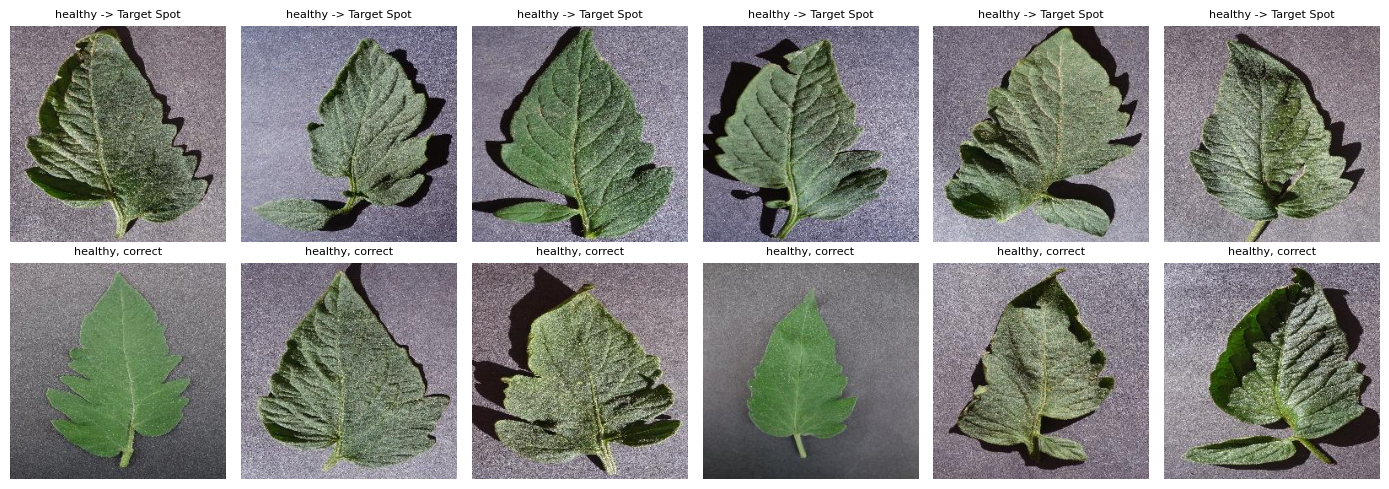

In [ ]:
import copy, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from src.trainer import evaluate_full

ckpt = f"{PROJECT_ROOT}/checkpoints/E0_seed123.pt"
m = get_resnet18(CONFIG["num_classes"], False, 0.0).to(device)
m.load_state_dict(torch.load(ckpt, map_location=device))
base = evaluate_full(m, val_loader, device, class_names=class_names)
print(
    "as saved: acc",
    round(base["accuracy"], 4),
    "| Tomato_healthy recall",
    round(base["class_report"]["Tomato_healthy"]["recall"], 3),
)

# Test 1: re-estimate BatchNorm statistics on train data, weights unchanged
m2 = copy.deepcopy(m)
for mod in m2.modules():
    if isinstance(mod, torch.nn.BatchNorm2d):
        mod.reset_running_stats()
        mod.momentum = None  # cumulative average over the batches below
m2.train()
with torch.no_grad():
    for i, (x, _) in enumerate(train_loader):
        m2(x.to(device))
        if i >= 100:
            break
r2 = evaluate_full(m2, val_loader, device, class_names=class_names)
print(
    "after BN recalibration: acc",
    round(r2["accuracy"], 4),
    "| Tomato_healthy recall",
    round(r2["class_report"]["Tomato_healthy"]["recall"], 3),
)

# Test 2: look at the misclassified images
samples = val_loader.dataset.samples
preds, targets = np.array(base["preds"]), np.array(base["targets"])
h = class_names.index("Tomato_healthy")
t = class_names.index("Tomato__Target_Spot")
wrong = np.where((targets == h) & (preds == t))[0]
right = np.where((targets == h) & (preds == h))[0]
print(len(wrong), "healthy images predicted as Target Spot")
print([Path(samples[i][0]).name for i in wrong[:10]])
fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for a, i in zip(ax[0], wrong[:6]):
    a.imshow(Image.open(samples[i][0]))
    a.set_title("healthy -> Target Spot", fontsize=8)
    a.axis("off")
for a, i in zip(ax[1], right[:6]):
    a.imshow(Image.open(samples[i][0]))
    a.set_title("healthy, correct", fontsize=8)
    a.axis("off")
plt.tight_layout()
plt.show()

# BatchNorm control on all three E0 checkpoints, plus file-name prefix count (I-16)

In [ ]:
from collections import Counter


def recal_bn(model, loader, device, n_batches=100):
    m2 = copy.deepcopy(model)
    for mod in m2.modules():
        if isinstance(mod, torch.nn.BatchNorm2d):
            mod.reset_running_stats()
            mod.momentum = None
    m2.train()
    with torch.no_grad():
        for i, (x, _) in enumerate(loader):
            m2(x.to(device))
            if i >= n_batches:
                break
    return m2


for seed in [0, 42, 123]:
    mm = get_resnet18(CONFIG["num_classes"], False, 0.0).to(device)
    mm.load_state_dict(torch.load(f"{PROJECT_ROOT}/checkpoints/E0_seed{seed}.pt", map_location=device))
    a = evaluate_full(mm, val_loader, device, class_names=class_names)
    b = evaluate_full(recal_bn(mm, train_loader, device), val_loader, device, class_names=class_names)
    print(f'seed {seed}: as saved {a["accuracy"]:.4f} | BN recalibrated {b["accuracy"]:.4f}')


def prefix(i):
    return Path(samples[i][0]).name.split("___", 1)[-1].split(" ")[0]


print("misclassified healthy, by file prefix:", Counter(prefix(i) for i in wrong))
print("correct healthy, by file prefix:      ", Counter(prefix(i) for i in right))

seed 0: as saved 0.9971 | BN recalibrated 0.9976
seed 42: as saved 0.9971 | BN recalibrated 0.9971
seed 123: as saved 0.9728 | BN recalibrated 0.9922
misclassified healthy, by file prefix: Counter({'RS_HL': 38, 'GH_HL': 1})
correct healthy, by file prefix:       Counter({'RS_HL': 58, 'GH_HL': 57})


# Duplicate-image check

In [ ]:
import hashlib, collections
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

DATA = Path("/content/data")
MAX_GROUPS = 12  # how many duplicate groups to display

# 1. Hash every file, remembering which split it came from
by_hash = collections.defaultdict(list)
for split in ["train", "val", "test"]:
    for p in (DATA / split).rglob("*.*"):
        if p.is_file():
            by_hash[hashlib.md5(p.read_bytes()).hexdigest()].append((split, p))

# 2. Keep only hashes that appear in more than one split
cross = {h: v for h, v in by_hash.items() if len({s for s, _ in v}) > 1}

# 3. Summary
n_files = sum(len(v) for v in cross.values())
print(f"{len(cross)} duplicate groups spanning splits ({n_files} files in total)")
pairs = collections.Counter(tuple(sorted({s for s, _ in v})) for v in cross.values())
for combo, n in pairs.items():
    print(f'  {" + ".join(combo)}: {n} groups')

# 4. Show the images: one row per group, one column per copy
groups = list(cross.values())[:MAX_GROUPS]
if groups:
    n_cols = max(len(g) for g in groups)
    fig, axes = plt.subplots(len(groups), n_cols, figsize=(3.2 * n_cols, 3.4 * len(groups)), squeeze=False)
    for row, group in enumerate(groups):
        for col in range(n_cols):
            ax = axes[row, col]
            ax.axis("off")
            if col < len(group):
                split, path = group[col]
                ax.imshow(Image.open(path).convert("RGB"))
                # class folder + filename, split in bold on the first line
                ax.set_title(f"{split.upper()}\n{path.parent.name[:28]}\n{path.name[:28]}", fontsize=8)
    plt.tight_layout()
    plt.show()

0 duplicate groups spanning splits (0 files in total)


In [ ]:
import re, collections


def leaf_key(path):
    return path.split("/")[-1].split("___", 1)[-1].lower()


train_keys = {
    leaf_key(p.relative_to(DATA / "train").as_posix()) for p in (DATA / "train").rglob("*.*") if p.is_file()
}
for split in ["val", "test"]:
    files = [p.relative_to(DATA / split).as_posix() for p in (DATA / split).rglob("*.*") if p.is_file()]
    shared = [f for f in files if leaf_key(f) in train_keys]
    print(split, len(shared), "of", len(files), "share a leaf key with train")

val 4 of 2064 share a leaf key with train
test 1 of 2070 share a leaf key with train


# Dataset: file-name prefix (capture series) per class in the train set

In [ ]:
import pandas as pd

rows = []
for path, label in train_loader.dataset.samples:
    pre = Path(path).name.split("___", 1)[-1].split(" ")[0]
    rows.append((class_names[label], pre))
df = pd.DataFrame(rows, columns=["class", "prefix"])
print(df.groupby(["class", "prefix"]).size().unstack(fill_value=0).to_string())

prefix                                       2700323949_95aa2eaa01_o.jpg  CG1.JPG  Com.G_SpM_FL  Com.G_TgS_FL  Crnl_L.Mold  GCREC_Bact.Sp  GHLB  GHLB2  GHLB2ES  GHLB_PS  GH_HL  JR_B.Spot  JR_HL  JR_Sept.L.S  Keller.St_CG  Matt.S_CG  NREC_B.Spot  PSU_CG  RS_Early.B  RS_Erly.B  RS_HL  RS_LB  RS_Late.B  Screen  UF.GRC_BS_Lab  UF.GRC_YLCV_Lab  YLCV_GCREC  YLCV_NREC  bell-pepper-plant-61726.jpg
class                                                                                                                                                                                                                                                                                                                                                                                                   
Pepper__bell___Bacterial_spot                                          0        0             0             0            0              0     0      0        0        0      0        462      0            0        

# Leakage check (I-7): do val/test images share a leaf id with train images?

In [ ]:
import re


def leaf_id(name):
    stem = name.split("___", 1)[-1]
    m = re.match(r"(\S+) Leaf (\d+(?:\.\d+)?)", stem)  # e.g. "GHLB_PS Leaf 23.7 Day 13.jpg"
    return (m.group(1), m.group(2)) if m else None


train_ids = {leaf_id(Path(p).name) for p, _ in train_loader.dataset.samples} - {None}
for name, loader in [("val", val_loader), ("test", test_loader)]:
    items = [(Path(p).name, c) for p, c in loader.dataset.samples]
    with_id = [n for n, c in items if leaf_id(n) is not None]
    shared = [n for n in with_id if leaf_id(n) in train_ids]
    print(name, "images with a leaf id:", len(with_id), "| sharing a leaf id with train:", len(shared))

val images with a leaf id: 182 | sharing a leaf id with train: 6
test images with a leaf id: 177 | sharing a leaf id with train: 10


# Leakage check 2 (I-7): leaf-map.json from Hugging Face, coverage of our files

In [ ]:
import json, re, urllib.request
from pathlib import Path

url = "https://huggingface.co/datasets/mohanty/PlantVillage/resolve/main/leaf_grouping/leaf-map.json"
leaf_map = json.load(urllib.request.urlopen(url))
print(type(leaf_map), "entries:", len(leaf_map))
for k in list(leaf_map)[:5]:
    print(repr(k), "->", leaf_map[k])


def hf_key(filename):
    name = filename.replace("_final_masked", "")
    if "___" in name:
        name = name.split("___", 1)[-1]
    name = name.split("copy")[0]
    name = re.sub(r"\.(jpg|jpeg|png)$", "", name, flags=re.I)
    return name.lower().strip()


for split, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    keys = [hf_key(Path(p).name) for p, _ in loader.dataset.samples]
    found = sum(k in leaf_map for k in keys)
    print(split, "files:", len(keys), "| key found in leaf map:", found)

<class 'dict'> entries: 40328
'rutg._hl 3733' -> ['Peach___healthy:::54.0']
'com.g_fl 8310' -> ['Tomato___Target_Spot:::243.0']
'rs_early.b 7557' -> ['Potato___Early_blight:::115.0']
'rs_early.b 7554' -> ['Potato___Early_blight:::115.0']
'uf.citrus_hlb_lab 1658' -> ['Orange___Haunglongbing_(Citrus_greening):::104.0']
train files: 16504 | key found in leaf map: 11923
val files: 2060 | key found in leaf map: 1500
test files: 2069 | key found in leaf map: 1512


# Leakage check 3 (I-7): val/test images that share a leaf group with train, using the leaf map

In [ ]:
import collections


def norm(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())


def leaf_group(path, class_name):
    sug = leaf_map.get(hf_key(Path(path).name))
    if not sug:
        return None
    for s in sug:
        cls, _, gid = s.partition(":::")
        if norm(cls) == norm(class_name):
            return s
    return None


groups = {}
for split, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    groups[split] = [leaf_group(p, class_names[l]) for p, l in loader.dataset.samples]
    print(
        split, "linked to a leaf group:", sum(g is not None for g in groups[split]), "of", len(groups[split])
    )

train_groups = {g for g in groups["train"] if g is not None}
for split, loader in [("val", val_loader), ("test", test_loader)]:
    linked = [
        (g, class_names[l]) for g, (p, l) in zip(groups[split], loader.dataset.samples) if g is not None
    ]
    shared = [(g, c) for g, c in linked if g in train_groups]
    n_all = len(loader.dataset.samples)
    print(
        f"{split}: linked {len(linked)} | sharing a leaf group with train: {len(shared)} "
        f"({len(shared)/len(linked):.1%} of linked, {len(shared)/n_all:.1%} of all)"
    )
    print("  shared by class:", dict(collections.Counter(c for _, c in shared)))

print("\nTrain coverage per class (linked / total):")
cov = collections.defaultdict(lambda: [0, 0])
for g, (p, l) in zip(groups["train"], train_loader.dataset.samples):
    cov[class_names[l]][1] += 1
    if g is not None:
        cov[class_names[l]][0] += 1
for c, (a, b) in cov.items():
    print(f"  {c:45s} {a}/{b}")

train linked to a leaf group: 11923 of 16504
val linked to a leaf group: 1500 of 2060
test linked to a leaf group: 1512 of 2069
val: linked 1500 | sharing a leaf group with train: 1478 (98.5% of linked, 71.7% of all)
  shared by class: {'Pepper__bell___Bacterial_spot': 100, 'Pepper__bell___healthy': 148, 'Potato___Early_blight': 98, 'Potato___Late_blight': 98, 'Potato___healthy': 15, 'Tomato_Bacterial_spot': 213, 'Tomato_Early_blight': 100, 'Tomato_Late_blight': 92, 'Tomato_Leaf_Mold': 95, 'Tomato_Septoria_leaf_spot': 104, 'Tomato_Spider_mites_Two_spotted_spider_mite': 168, 'Tomato__Tomato_YellowLeaf__Curl_Virus': 148, 'Tomato_healthy': 99}
test: linked 1512 | sharing a leaf group with train: 1496 (98.9% of linked, 72.3% of all)
  shared by class: {'Pepper__bell___Bacterial_spot': 100, 'Pepper__bell___healthy': 148, 'Potato___Early_blight': 98, 'Potato___Late_blight': 98, 'Potato___healthy': 16, 'Tomato_Bacterial_spot': 213, 'Tomato_Early_blight': 100, 'Tomato_Late_blight': 101, 'Tomat

# Leaf group sizes and image-number spans (does consecutive numbering match the leaf groups?)

In [ ]:
# Needs groups, Path, re, train/val/test loaders.
import pandas as pd

rows = []
for split, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    for g, (p, l) in zip(groups[split], loader.dataset.samples):
        if g is None:
            continue
        name = Path(p).name.split("___", 1)[-1]
        m = re.search(r"(\d+)\.[A-Za-z]+$", name)
        rows.append((g, split, int(m.group(1)) if m else None, name.split(" ")[0]))
df = pd.DataFrame(rows, columns=["group", "split", "num", "prefix"])

size = df.groupby("group").size()
print(
    "leaf groups:",
    len(size),
    "| images per group: median",
    size.median(),
    "mean",
    round(size.mean(), 1),
    "max",
    size.max(),
)
span = df.dropna().groupby("group")["num"].agg(lambda x: x.max() - x.min())
print(
    "image-number span inside a group: median",
    span.median(),
    "| 90th percentile",
    span.quantile(0.9),
    "| max",
    span.max(),
)
n_splits = df.groupby("group")["split"].nunique()
print("groups spread over 2 or more splits:", int((n_splits > 1).sum()), "of", len(n_splits))

leaf groups: 3717 | images per group: median 4.0 mean 4.0 max 17
image-number span inside a group: median 3.0 | 90th percentile 7.0 | max 7390
groups spread over 2 or more splits: 2125 of 3717


# Leaf-grouped split, step 1: group keys and proxy test (writes nothing)

In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

items = []
for split, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    for g, (p, l) in zip(groups[split], loader.dataset.samples):
        items.append({"path": p, "cls": class_names[l], "split": split, "leafmap": g})
df = pd.DataFrame(items)
df["name"] = df["path"].map(lambda p: Path(p).name.split("___", 1)[-1])
df["prefix"] = df["name"].map(lambda n: n.split(" ")[0])


def get_num(n):
    m = re.search(r"(\d+)\.[A-Za-z]+$", n)
    return int(m.group(1)) if m else -1


df["num"] = df["name"].map(get_num)


def get_leafnum(n):
    m = re.match(r"(\S+) Leaf (\d+(?:\.\d+)?)", n)
    return f"{m.group(1)}|leaf{m.group(2)}" if m else None


df["leafnum"] = df["name"].map(get_leafnum)


def method(r):
    if pd.notna(r["leafmap"]):
        return "leafmap"
    if r["leafnum"] is not None:
        return "leafnum"
    return "proxy"


df["method"] = df.apply(method, axis=1)
print("images per method:", df["method"].value_counts().to_dict())
print(df.groupby(["cls", "method"]).size().unstack(fill_value=0).to_string())


def bucket_key(d, B):
    k = d["cls"] + "|" + d["prefix"] + "|b" + (d["num"] // B).astype(str)
    return k.where(d["num"] >= 0, d["path"])  # unparseable name: image is its own group


def residual_leakage(d, key, seed=0):
    d = d.copy()
    d["k"] = key
    fold = np.full(len(d), -1)
    sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed)
    for f, (_, idx) in enumerate(sgkf.split(d, d["cls"], groups=d["k"])):
        fold[idx] = f
    d["fold"] = fold
    return (d.groupby("leafmap")["fold"].nunique() > 1).mean()


lk = df[df["leafmap"].notna()].reset_index(drop=True)
print("\nShare of true leaf groups still cut across folds, linked images only:")
print("  random image split :", f"{residual_leakage(lk, lk['path']):.1%}")
for B in (8, 16, 32, 64):
    k = bucket_key(lk, B)
    print(
        f"  bucket size {B:>3}    :",
        f"{residual_leakage(lk, k):.1%}",
        f"| buckets: {k.nunique()} | median bucket size: {k.value_counts().median():.0f}",
    )

images per method: {'leafmap': 14935, 'proxy': 4126, 'leafnum': 1572}
method                                       leafmap  leafnum  proxy
cls                                                                 
Pepper__bell___Bacterial_spot                    997        0      0
Pepper__bell___healthy                          1476        0      2
Potato___Early_blight                           1000        0      0
Potato___Late_blight                            1000        0      0
Potato___healthy                                 152        0      0
Tomato_Bacterial_spot                           2127        0      0
Tomato_Early_blight                              999        0      1
Tomato_Late_blight                               920      984      2
Tomato_Leaf_Mold                                 952        0      0
Tomato_Septoria_leaf_spot                       1000        0    771
Tomato_Spider_mites_Two_spotted_spider_mite     1676        0      0
Tomato__Target_Spot              

# Leaf-grouped split, step 2: build the new split and write splits.json (DO NOT RUN)

In [ ]:
import json, shutil
from src.dataset import MANIFEST_PATH, TRAIN_DIR, VAL_DIR, TEST_DIR

B = 64  # bucket size for images without a leaf group (chosen in step 1)
SEED = 0
DATA = Path("/content/data")
mp = Path(MANIFEST_PATH)
csv_out = mp.with_name("split_groups_v3.csv")
assert not csv_out.exists(), "Grouped split already written. Do not run this cell again."

# 1. Group key per image: leaf map, then leaf number in the name, then the number bucket
bk = bucket_key(df, B)


def pick(i):
    r = df.loc[i]
    if r["method"] == "leafmap":
        return "lm|" + r["leafmap"]
    if r["method"] == "leafnum":
        return r["cls"] + "|ln|" + r["leafnum"]
    return "px|" + bk[i]


df["group"] = [pick(i) for i in df.index]

# 2. Stratified group split: fold 0 = test, fold 1 = val, folds 2 to 9 = train
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
df["fold"] = -1
for f, (_, idx) in enumerate(sgkf.split(df, df["cls"], groups=df["group"])):
    df.loc[df.index[idx], "fold"] = f
df["new_split"] = np.where(df["fold"] == 0, "test", np.where(df["fold"] == 1, "val", "train"))

# 3. Checks
assert df.groupby("group")["new_split"].nunique().max() == 1, "a group is spread over splits"
print("split sizes:", df["new_split"].value_counts().to_dict())
tab = df.groupby(["cls", "new_split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
tab["all"] = tab.sum(axis=1)
print(tab.to_string())

# 4. Write the new split (the current dedup split is backed up, the original is splits_v1.json)
df["rel"] = [Path(p).relative_to(DATA / s).as_posix() for p, s in zip(df["path"], df["split"])]
manifest = {s: df.loc[df["new_split"] == s, "rel"].tolist() for s in ["train", "val", "test"]}
backup = mp.with_name("splits_v2_dedup.json")
if not backup.exists():
    shutil.copy(mp, backup)
json.dump(manifest, open(mp, "w"))
df[["rel", "cls", "method", "group", "new_split"]].to_csv(csv_out, index=False)
for d in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    shutil.rmtree(d, ignore_errors=True)
print("New splits.json written, local data folders deleted. Re-run code cell 2 to rebuild the data.")

split sizes: {'train': 16411, 'test': 2113, 'val': 2109}
new_split                                    train  val  test   all
cls                                                                
Pepper__bell___Bacterial_spot                  750  115   132   997
Pepper__bell___healthy                        1215  144   119  1478
Potato___Early_blight                          792  100   108  1000
Potato___Late_blight                           800  104    96  1000
Potato___healthy                               120   16    16   152
Tomato_Bacterial_spot                         1683  240   204  2127
Tomato_Early_blight                            812   92    96  1000
Tomato_Late_blight                            1529  194   183  1906
Tomato_Leaf_Mold                               776   80    96   952
Tomato_Septoria_leaf_spot                     1514  100   157  1771
Tomato_Spider_mites_Two_spotted_spider_mite   1344  168   164  1676
Tomato__Target_Spot                           1150  254    

# Leaf-grouped split, step 2b: balanced assignment per class (REPLACES the step 2 result, DO NOT RUN)

In [ ]:
from src.dataset import MANIFEST_PATH, TRAIN_DIR, VAL_DIR, TEST_DIR

SEED = 0
targets = {"train": 0.8, "val": 0.1, "test": 0.1}
mp = Path(MANIFEST_PATH)
csv_out = mp.with_name("split_groups_v3.csv")

# 1. Per class: biggest groups first (random order among equal sizes),
#    each group goes to the split that is furthest below its target share
assign = {}
for cls, dc in df.groupby("cls"):
    sizes = dc.groupby("group").size()
    order = sizes.sample(frac=1, random_state=SEED).sort_values(ascending=False, kind="stable")
    n = len(dc)
    cur = {s: 0 for s in targets}
    for g, sz in order.items():
        s = max(targets, key=lambda k: (targets[k] * n - cur[k]) / (targets[k] * n))
        assign[g] = s
        cur[s] += sz
df["new_split"] = df["group"].map(assign)

# 2. Checks
assert df["new_split"].notna().all()
assert df.groupby("group")["new_split"].nunique().max() == 1, "a group is spread over splits"
tab = df.groupby(["cls", "new_split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
tab["all"] = tab.sum(axis=1)
tab["val %"] = (100 * tab["val"] / tab["all"]).round(1)
tab["test %"] = (100 * tab["test"] / tab["all"]).round(1)
print("split sizes:", df["new_split"].value_counts().to_dict())
print(tab.to_string())
assert (tab[["train", "val", "test"]] > 0).all().all(), "a class has an empty split, do NOT continue"

# 3. Write the new split and force the data to be rebuilt
manifest = {s: df.loc[df["new_split"] == s, "rel"].tolist() for s in ["train", "val", "test"]}
json.dump(manifest, open(mp, "w"))
df[["rel", "cls", "method", "group", "new_split"]].to_csv(csv_out, index=False)
for d in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    shutil.rmtree(d, ignore_errors=True)
print("Balanced grouped split written. Re-run code cell 2 to rebuild the data.")

split sizes: {'train': 16398, 'val': 2124, 'test': 2111}
new_split                                    train  val  test   all  val %  test %
cls                                                                               
Pepper__bell___Bacterial_spot                  797  100   100   997   10.0    10.0
Pepper__bell___healthy                        1182  148   148  1478   10.0    10.0
Potato___Early_blight                          800  100   100  1000   10.0    10.0
Potato___Late_blight                           800  100   100  1000   10.0    10.0
Potato___healthy                               120   16    16   152   10.5    10.5
Tomato_Bacterial_spot                         1700  215   212  2127   10.1    10.0
Tomato_Early_blight                            800  100   100  1000   10.0    10.0
Tomato_Late_blight                            1524  191   191  1906   10.0    10.0
Tomato_Leaf_Mold                               760   96    96   952   10.1    10.1
Tomato_Septoria_leaf_spot     

# Leaf-grouped split v4: finer proxy buckets (B=32), balanced per-class assignment (REPLACES splits.json, DO NOT RUN)

In [ ]:
import os, re, json, shutil
import pandas as pd
from pathlib import Path
from src.dataset import MANIFEST_PATH, TRAIN_DIR, VAL_DIR, TEST_DIR

B_DEFAULT = 32
B_OVERRIDE = {}  # per-class bucket size, e.g. {'Tomato__Tomato_mosaic_virus': 16}
SEED = 0
targets = {"train": 0.8, "val": 0.1, "test": 0.1}

mp = Path(MANIFEST_PATH)
csv_old = mp.with_name("split_groups_v3.csv")
csv_new = mp.with_name("split_groups_v4.csv")
assert not csv_new.exists(), "v4 split already written, do NOT run this cell twice"
shutil.copy(mp, mp.with_name("splits_v3_b64.json"))
shutil.copy(csv_old, mp.with_name("split_groups_v3_b64.csv"))
df = pd.read_csv(csv_old)


def img_num(rel):
    name = os.path.basename(rel).split("___", 1)[-1]
    nums = re.findall(r"\d+", os.path.splitext(name)[0])
    return int(nums[-1]) if nums else None


is_bucket = (df["method"] == "proxy") & df["group"].str.contains(r"\|b\d+$", regex=True)
nums = df.loc[is_bucket, "rel"].map(img_num)
old_b = df.loc[is_bucket, "group"].str.extract(r"\|b(\d+)$")[0].astype(int)
match = ((nums // 64) == old_b).mean()
print(f"bucket proxy rows: {is_bucket.sum()}, old bucket reproduced from file name for {match:.1%}")
assert match > 0.95, "file-name number parsing does not reproduce the old buckets, do NOT continue"


def new_key(row, num):
    B = B_OVERRIDE.get(row["cls"], B_DEFAULT)
    return re.sub(r"\|b\d+$", f"|B{B}_{int(num) // B}", row["group"])


df.loc[is_bucket, "group"] = [new_key(df.loc[i], n) for i, n in nums.items()]

# 2. Per class: biggest groups first, each to the split furthest below its 80/10/10 target
assign = {}
for cls, dc in df.groupby("cls"):
    sizes = dc.groupby("group").size()
    order = sizes.sample(frac=1, random_state=SEED).sort_values(ascending=False, kind="stable")
    n = len(dc)
    cur = {s: 0 for s in targets}
    for g, sz in order.items():
        s = max(targets, key=lambda k: (targets[k] * n - cur[k]) / (targets[k] * n))
        assign[g] = s
        cur[s] += sz
df["new_split"] = df["group"].map(assign)

# 3. Checks
assert df["new_split"].notna().all()
assert df.groupby("group")["new_split"].nunique().max() == 1, "a group is spread over splits"
tab = df.groupby(["cls", "new_split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
tab["all"] = tab.sum(axis=1)
tab["val %"] = (100 * tab["val"] / tab["all"]).round(1)
tab["test %"] = (100 * tab["test"] / tab["all"]).round(1)
print("split sizes:", df["new_split"].value_counts().to_dict())
print(tab.to_string())
assert (tab[["train", "val", "test"]] > 0).all().all(), "a class has an empty split, do NOT continue"
rows = []
for split in ["val", "test"]:
    d = df[df["new_split"] == split]
    n = d.groupby("cls").size()
    top = d.groupby(["cls", "group"]).size().groupby("cls").max()
    rows += [(split, c, int(n[c]), int(top[c]), round(top[c] / n[c], 3)) for c in n.index]
print(
    pd.DataFrame(rows, columns=["split", "class", "n_images", "largest_group", "share"])
    .sort_values("share", ascending=False)
    .head(8)
    .to_string(index=False)
)

# 4. Write the new split and force the data to be rebuilt
manifest = {s: df.loc[df["new_split"] == s, "rel"].tolist() for s in ["train", "val", "test"]}
json.dump(manifest, open(mp, "w"))
df[["rel", "cls", "method", "group", "new_split"]].to_csv(csv_new, index=False)
for d in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    shutil.rmtree(d, ignore_errors=True)
print("v4 split written. Re-run code cell 2 to rebuild the data.")

bucket proxy rows: 4123, old bucket reproduced from file name for 100.0%
split sizes: {'train': 16456, 'val': 2100, 'test': 2077}
new_split                                    train  val  test   all  val %  test %
cls                                                                               
Pepper__bell___Bacterial_spot                  797  100   100   997   10.0    10.0
Pepper__bell___healthy                        1182  148   148  1478   10.0    10.0
Potato___Early_blight                          800  100   100  1000   10.0    10.0
Potato___Late_blight                           800  100   100  1000   10.0    10.0
Potato___healthy                               120   16    16   152   10.5    10.5
Tomato_Bacterial_spot                         1700  215   212  2127   10.1    10.0
Tomato_Early_blight                            800  100   100  1000   10.0    10.0
Tomato_Late_blight                            1524  191   191  1906   10.0    10.0
Tomato_Leaf_Mold                        

## 2. Run the experiment
Results are saved after every seed to `Project_deep/runs/<experiment>.json` and one row per run is appended to `Project_deep/runs/experiment_log.csv`. Finished seeds are skipped automatically, so it is safe to re-run after a disconnect.

In [ ]:
# Code cell 6 (run experiment). Keep.
saved = run_experiment(CONFIG, PROJECT_ROOT, device, eval_test=False, notes="")

E2: seeds already finished: []

--- running E2 | seed 0 | code version f0ab6407 ---
Epoch 1/10 | lr 1.00e-04 | train loss 0.2858 | val loss 0.0826 | val acc 0.9729 | val F1 0.9712 | 112.2s
Epoch 2/10 | lr 9.76e-05 | train loss 0.0709 | val loss 0.1245 | val acc 0.9624 | val F1 0.9477 | 112.3s
Epoch 3/10 | lr 9.05e-05 | train loss 0.0452 | val loss 0.0390 | val acc 0.9876 | val F1 0.9845 | 113.9s
Epoch 4/10 | lr 7.94e-05 | train loss 0.0340 | val loss 0.0565 | val acc 0.9819 | val F1 0.9780 | 112.6s
Epoch 5/10 | lr 6.55e-05 | train loss 0.0198 | val loss 0.0443 | val acc 0.9814 | val F1 0.9794 | 111.5s
Epoch 6/10 | lr 5.00e-05 | train loss 0.0128 | val loss 0.0285 | val acc 0.9910 | val F1 0.9891 | 111.3s
Epoch 7/10 | lr 3.45e-05 | train loss 0.0083 | val loss 0.0197 | val acc 0.9933 | val F1 0.9933 | 112.2s
Epoch 8/10 | lr 2.06e-05 | train loss 0.0074 | val loss 0.0206 | val acc 0.9924 | val F1 0.9918 | 112.8s
Epoch 9/10 | lr 9.55e-06 | train loss 0.0055 | val loss 0.0196 | val acc 0.9

## 3. Log and curves

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

csv_path = PROJECT_ROOT + "/runs/experiment_log.csv"
print(
    pd.read_csv(csv_path)[
        [
            "date",
            "experiment",
            "seed",
            "code_version",
            "val_acc",
            "val_macro_f1",
            "val_min_class_recall",
            "val_min_recall_class",
            "sec_per_epoch",
        ]
    ].to_string(index=False)
)
print()
print(summarise(csv_path))

            date experiment  seed code_version  val_acc  val_macro_f1  val_min_class_recall          val_min_recall_class  sec_per_epoch
2026-10-06 12:19         E0     0     7b699a0c  0.99709       0.99736               0.97895              Tomato_Leaf_Mold           73.6
2026-10-06 12:31         E0    42     7b699a0c  0.99709       0.99734               0.97857           Tomato__Target_Spot           73.7
2026-10-06 12:43         E0   123     7b699a0c  0.97282       0.97501               0.73248                Tomato_healthy           74.3
2026-10-20 14:26        E0g     0     f0ab6407  0.98540       0.98624               0.88757           Tomato__Target_Spot           65.5
2026-10-20 14:36        E0g    42     f0ab6407  0.98964       0.99016               0.95288            Tomato_Late_blight           65.4
2026-10-20 14:47        E0g   123     f0ab6407  0.98540       0.98448               0.92899           Tomato__Target_Spot           65.0
2026-10-21 06:50       E0g2     0     f0a

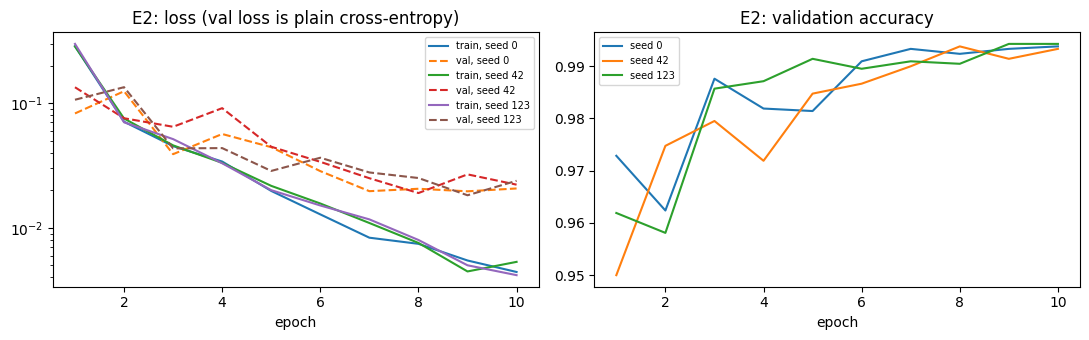

In [ ]:
# Train / validation loss and validation accuracy per epoch, one line per seed
exp = CONFIG["experiment_id"]
res = json.load(open(f"{PROJECT_ROOT}/runs/{exp}.json"))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for r in res["results"]:
    h = r["history"]
    ep = [x["epoch"] for x in h]
    ax[0].plot(ep, [x["train_loss"] for x in h], "-", label=f"train, seed {r['seed']}")
    ax[0].plot(ep, [x["val_loss"] for x in h], "--", label=f"val, seed {r['seed']}")
    ax[1].plot(ep, [x["val_acc"] for x in h], label=f"seed {r['seed']}")
ax[0].set_title(f"{exp}: loss (val loss is plain cross-entropy)")
ax[0].set_xlabel("epoch")
ax[0].set_yscale("log")
ax[0].legend(fontsize=7)
ax[1].set_title(f"{exp}: validation accuracy")
ax[1].set_xlabel("epoch")
ax[1].legend(fontsize=7)
plt.tight_layout()
plt.savefig(f"{PROJECT_ROOT}/runs/{exp}_curves.png", dpi=120)
plt.show()

                                      class  recall_mean  recall_min
                           Potato___healthy        0.875       0.812
      Tomato__Tomato_YellowLeaf__Curl_Virus        0.980       0.975
                        Tomato_Early_blight        0.987       0.980
                         Tomato_Late_blight        0.991       0.984
                Tomato__Tomato_mosaic_virus        0.994       0.981
                     Pepper__bell___healthy        0.995       0.993
                      Tomato_Bacterial_spot        0.998       0.995
                  Tomato_Septoria_leaf_spot        0.998       0.994
                      Potato___Early_blight        1.000       1.000
              Pepper__bell___Bacterial_spot        1.000       1.000
                       Potato___Late_blight        1.000       1.000
                           Tomato_Leaf_Mold        1.000       1.000
                        Tomato__Target_Spot        1.000       1.000
Tomato_Spider_mites_Two_spotted_sp

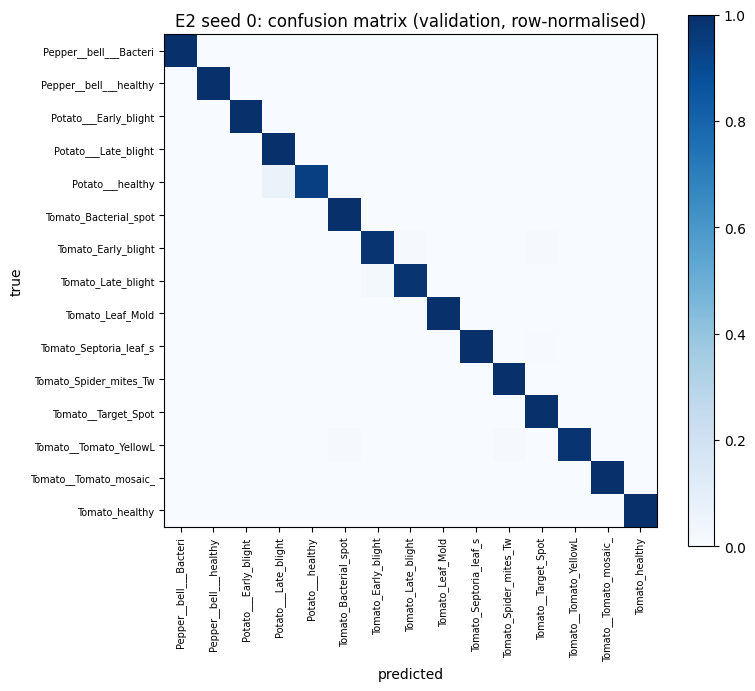

In [ ]:
# Per-class validation recall (all seeds) and confusion matrix for one seed
classes = res["classes"]
recall = np.array([[r["val"]["class_report"][c]["recall"] for c in classes] for r in res["results"]])
print(
    pd.DataFrame(
        {"class": classes, "recall_mean": recall.mean(0).round(3), "recall_min": recall.min(0).round(3)}
    )
    .sort_values("recall_mean")
    .to_string(index=False)
)

seed_idx = 0
cm = np.array(res["results"][seed_idx]["val"]["confusion_matrix"], dtype=float)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)))
ax.set_yticks(range(len(classes)))
ax.set_xticklabels([c[:22] for c in classes], rotation=90, fontsize=7)
ax.set_yticklabels([c[:22] for c in classes], fontsize=7)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f'{exp} seed {res["results"][seed_idx]["seed"]}: confusion matrix (validation, row-normalised)')
plt.colorbar(im)
plt.tight_layout()
plt.savefig(f"{PROJECT_ROOT}/runs/{exp}_confusion.png", dpi=120)
plt.show()

# BN recalibration on E0g checkpoints (diagnostic, reusable for later runs by changing EXP). Keep.

In [ ]:
import numpy as np, torch, torch.nn as nn
from src.dataset import build_dataloaders
from src.models import get_resnet18
from src.trainer import evaluate_full
from src.experiment import DEFAULTS

EXP = "E0ga"
cfg = {**DEFAULTS, **CONFIG}
train_loader, val_loader, _, class_names = build_dataloaders(
    "/content/data/train", "/content/data/val", "/content/data/test", cfg
)


def weakest(res):
    cm = np.array(res["confusion_matrix"], dtype=float)
    rec = np.diag(cm) / cm.sum(axis=1)
    i = int(rec.argmin())
    return rec[i], class_names[i]


for seed in cfg["seeds"]:
    model = get_resnet18(
        cfg["num_classes"], freeze_backbone=cfg["freeze_backbone"], dropout=cfg["dropout"]
    ).to(device)
    model.load_state_dict(torch.load(f"{PROJECT_ROOT}/checkpoints/{EXP}_seed{seed}.pt", map_location=device))
    before = evaluate_full(model, val_loader, device, class_names=class_names)
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.reset_running_stats()
            m.momentum = None  # plain average over all batches
    model.train()
    with torch.no_grad():
        for x, _ in train_loader:
            model(x.to(device))
    after = evaluate_full(model, val_loader, device, class_names=class_names)
    wb, nb = weakest(before)
    wa, na = weakest(after)
    print(
        f"seed {seed}: acc {before['accuracy']:.4f} -> {after['accuracy']:.4f} | "
        f"F1 {before['macro_f1']:.4f} -> {after['macro_f1']:.4f} | "
        f"weakest recall {wb:.3f} ({nb}) -> {wa:.3f} ({na})"
    )

seed 0: acc 0.9943 -> 0.9952 | F1 0.9947 -> 0.9955 | weakest recall 0.979 (Tomato_Late_blight) -> 0.981 (Tomato__Tomato_mosaic_virus)
seed 42: acc 0.9971 -> 0.9976 | F1 0.9977 -> 0.9982 | weakest recall 0.986 (Pepper__bell___healthy) -> 0.991 (Tomato__Tomato_YellowLeaf__Curl_Virus)
seed 123: acc 0.9948 -> 0.9957 | F1 0.9908 -> 0.9937 | weakest recall 0.875 (Potato___healthy) -> 0.938 (Potato___healthy)


In [ ]:
# Check which device Colab is using (one-off, do not keep).
import torch

print(device, torch.cuda.is_available())

cpu False


# Top confusion pairs for E0g, summed over seeds (analysis only, no training). Keep.

In [ ]:
import json, numpy as np

d = json.load(open(f"{PROJECT_ROOT}/runs/E0g.json"))
classes = d["classes"]
cm = sum(np.array(r["val"]["confusion_matrix"]) for r in d["results"])
pairs = [
    (cm[i, j], classes[i], classes[j])
    for i in range(len(classes))
    for j in range(len(classes))
    if i != j and cm[i, j] > 0
]
for n, t, p in sorted(pairs, reverse=True)[:10]:
    print(f"{int(n):3d} images (3 seeds summed): true {t} -> predicted {p}")

 36 images (3 seeds summed): true Tomato__Target_Spot -> predicted Tomato_Spider_mites_Two_spotted_spider_mite
  9 images (3 seeds summed): true Tomato_Late_blight -> predicted Tomato_Early_blight
  5 images (3 seeds summed): true Tomato_Early_blight -> predicted Tomato_Late_blight
  4 images (3 seeds summed): true Tomato_Septoria_leaf_spot -> predicted Tomato_Late_blight
  4 images (3 seeds summed): true Potato___Early_blight -> predicted Pepper__bell___Bacterial_spot
  3 images (3 seeds summed): true Tomato__Tomato_mosaic_virus -> predicted Tomato_Spider_mites_Two_spotted_spider_mite
  3 images (3 seeds summed): true Tomato_Septoria_leaf_spot -> predicted Tomato_Leaf_Mold
  3 images (3 seeds summed): true Pepper__bell___healthy -> predicted Tomato_Late_blight
  2 images (3 seeds summed): true Tomato_healthy -> predicted Tomato__Tomato_mosaic_virus
  2 images (3 seeds summed): true Tomato_Late_blight -> predicted Tomato_healthy


# Misclassified Target Spot images, E0g seed 0 (inspection only, no training). Keep.

19 misclassified Target Spot images


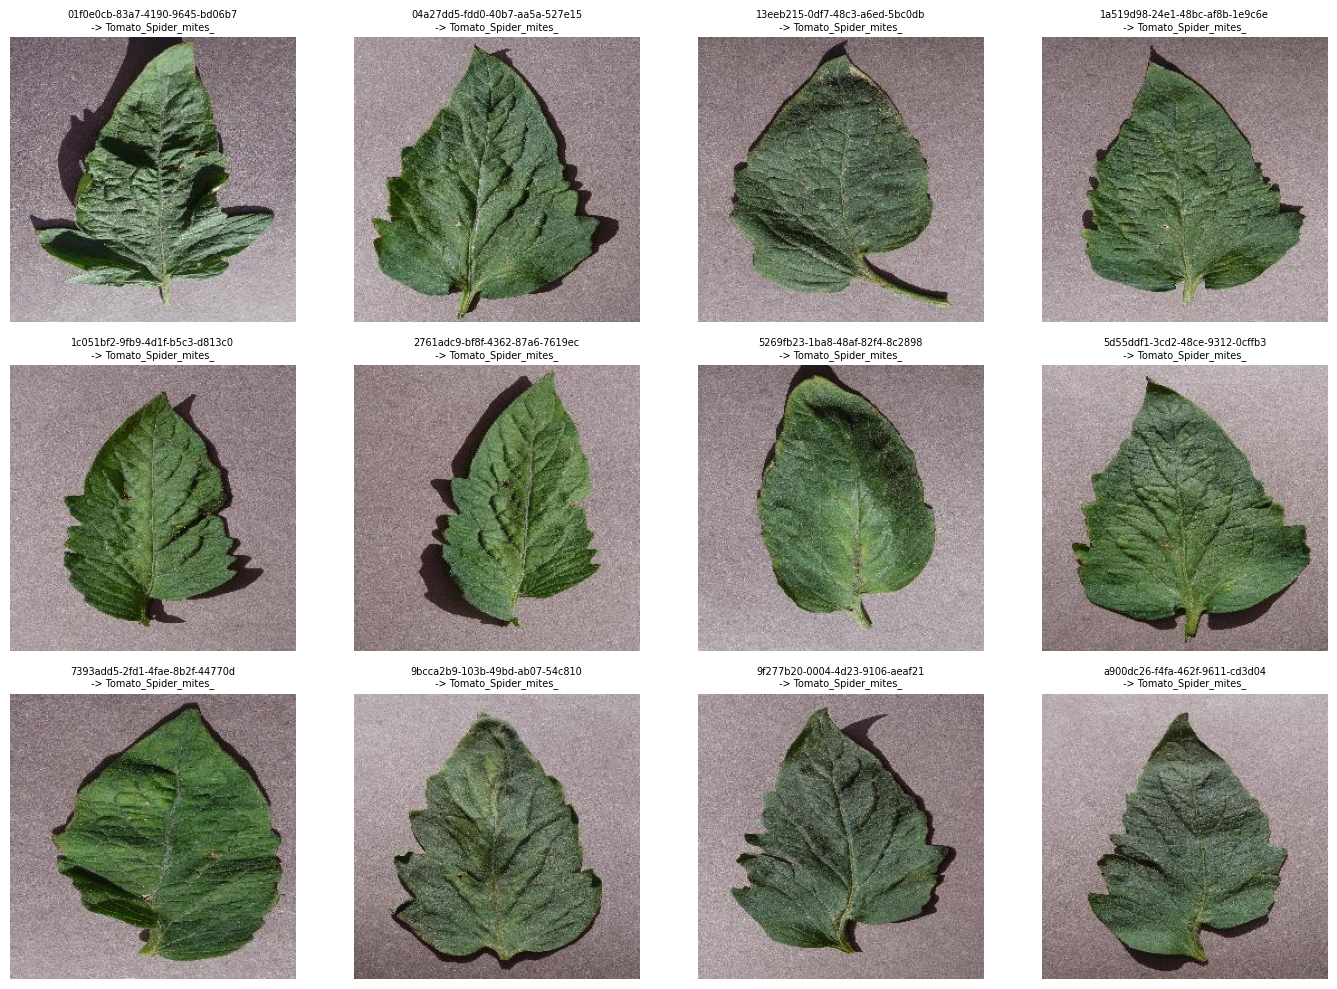

In [ ]:
import torch, matplotlib.pyplot as plt
from PIL import Image
from src.dataset import build_dataloaders
from src.models import get_resnet18
from src.trainer import evaluate_full
from src.experiment import DEFAULTS

cfg = {**DEFAULTS, **CONFIG}
_, val_loader, _, class_names = build_dataloaders(
    "/content/data/train", "/content/data/val", "/content/data/test", cfg
)
model = get_resnet18(cfg["num_classes"], freeze_backbone=cfg["freeze_backbone"], dropout=cfg["dropout"]).to(
    device
)
model.load_state_dict(torch.load(f"{PROJECT_ROOT}/checkpoints/E0g_seed0.pt", map_location=device))
res = evaluate_full(model, val_loader, device, class_names=class_names)

paths = [p for p, _ in val_loader.dataset.samples]  # assumes an ImageFolder dataset, same order as preds
t = class_names.index("Tomato__Target_Spot")
wrong = [i for i, (y, p) in enumerate(zip(res["targets"], res["preds"])) if y == t and p != t]
print(len(wrong), "misclassified Target Spot images")
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, i in zip(axes.ravel(), wrong[:12]):
    ax.imshow(Image.open(paths[i]))
    ax.axis("off")
    ax.set_title(f"{paths[i].split('/')[-1][:30]}\n-> {class_names[res['preds'][i]][:20]}", fontsize=7)
plt.tight_layout()
plt.show()

In [ ]:
# File name tails of the misclassified Target Spot images, seed 0 (inspection only). Keep.
for i in wrong:
    print(paths[i].split("/")[-1][-26:], "->", class_names[res["preds"][i]][:22])

65___Com.G_TgS_FL 8318.JPG -> Tomato_Spider_mites_Tw
99___Com.G_TgS_FL 9679.JPG -> Tomato_Spider_mites_Tw
5f___Com.G_TgS_FL 9723.JPG -> Tomato_Spider_mites_Tw
e8___Com.G_TgS_FL 9678.JPG -> Tomato_Spider_mites_Tw
ca___Com.G_TgS_FL 9683.JPG -> Tomato_Spider_mites_Tw
be___Com.G_TgS_FL 9681.JPG -> Tomato_Spider_mites_Tw
ec___Com.G_TgS_FL 9694.JPG -> Tomato_Spider_mites_Tw
3f___Com.G_TgS_FL 9676.JPG -> Tomato_Spider_mites_Tw
69___Com.G_TgS_FL 9719.JPG -> Tomato_Spider_mites_Tw
32___Com.G_TgS_FL 9684.JPG -> Tomato_Spider_mites_Tw
ad___Com.G_TgS_FL 9671.JPG -> Tomato_Spider_mites_Tw
4e___Com.G_TgS_FL 9668.JPG -> Tomato_Spider_mites_Tw
36___Com.G_TgS_FL 1109.JPG -> Tomato_Spider_mites_Tw
7e___Com.G_TgS_FL 9687.JPG -> Tomato_Spider_mites_Tw
5d___Com.G_TgS_FL 9702.JPG -> Tomato_Spider_mites_Tw
52___Com.G_TgS_FL 9677.JPG -> Tomato_Spider_mites_Tw
04___Com.G_TgS_FL 9680.JPG -> Tomato_Spider_mites_Tw
50___Com.G_TgS_FL 9720.JPG -> Tomato_Spider_mites_Tw
01___Com.G_TgS_FL 9682.JPG -> Tomato_Spider_mi

In [ ]:
# Target Spot capture run check: images with numbers 9664 to 9727 per split (inspection only). Keep.
import re, os, glob

pat = re.compile(r"Com\.G_TgS_FL (\d+)")
lo, hi = 9664, 9727
for split in ["train", "val", "test"]:
    files = glob.glob(f"/content/data/{split}/Tomato__Target_Spot/*")
    nums = [int(m.group(1)) for f in files if (m := pat.search(os.path.basename(f)))]
    print(
        f"{split}: {len(files)} Target Spot images, {len(nums)} with prefix Com.G_TgS_FL, "
        f"{sum(lo <= n <= hi for n in nums)} with number in {lo}-{hi}"
    )
wrong_in = sum(
    1 for i in wrong if (m := pat.search(os.path.basename(paths[i]))) and lo <= int(m.group(1)) <= hi
)
print(f"seed 0 val errors inside the range: {wrong_in} of {len(wrong)}")

train: 1077 Target Spot images, 1077 with prefix Com.G_TgS_FL, 0 with number in 9664-9727
val: 169 Target Spot images, 169 with prefix Com.G_TgS_FL, 63 with number in 9664-9727
test: 158 Target Spot images, 158 with prefix Com.G_TgS_FL, 0 with number in 9664-9727
seed 0 val errors inside the range: 17 of 19


In [ ]:
# Largest group share per class in val and test (split diagnostic, no training). Keep.
import pandas as pd

df = pd.read_csv(f"{PROJECT_ROOT}/split_groups_v3.csv")
print(df.columns.tolist())  # expected: rel, cls, method, group, new_split
rows = []
for split in ["val", "test"]:
    d = df[df["new_split"] == split]
    n = d.groupby("cls").size()
    top = d.groupby(["cls", "group"]).size().groupby("cls").max()
    for c in n.index:
        rows.append((split, c, int(n[c]), int(top[c]), round(top[c] / n[c], 3)))
out = pd.DataFrame(rows, columns=["split", "class", "n_images", "largest_group", "share"])
print(out.sort_values("share", ascending=False).head(12).to_string(index=False))

['rel', 'cls', 'method', 'group', 'new_split']
split                                 class  n_images  largest_group  share
  val           Tomato__Tomato_mosaic_virus        64             64  1.000
 test           Tomato__Tomato_mosaic_virus        64             64  1.000
 test                   Tomato__Target_Spot       158             64  0.405
  val                   Tomato__Target_Spot       169             64  0.379
  val             Tomato_Septoria_leaf_spot       177             64  0.362
 test             Tomato_Septoria_leaf_spot       178             64  0.360
 test                      Potato___healthy        16              4  0.250
  val                      Potato___healthy        16              4  0.250
  val         Pepper__bell___Bacterial_spot       100             17  0.170
 test         Pepper__bell___Bacterial_spot       100             16  0.160
  val Tomato__Tomato_YellowLeaf__Curl_Virus       321             44  0.137
 test Tomato__Tomato_YellowLeaf__Curl_Vir

In [ ]:
print(df["method"].value_counts())
print(df.groupby("method").head(3).sort_values("method").to_string(index=False))

method
leafmap    14935
proxy       4126
leafnum     1572
Name: count, dtype: int64
                                                                                                   rel                           cls  method                                                                                                                         group new_split
               Pepper__bell___Bacterial_spot/0022d6b7-d47c-4ee2-ae9a-392a53f48647___JR_B.Spot 8964.JPG Pepper__bell___Bacterial_spot leafmap                                                                                    lm|Pepper,_bell___Bacterial_spot:::JR_51.0     train
               Pepper__bell___Bacterial_spot/006adb74-934f-448f-a14f-62181742127b___JR_B.Spot 3395.JPG Pepper__bell___Bacterial_spot leafmap                                                                                    lm|Pepper,_bell___Bacterial_spot:::JR_27.0       val
               Pepper__bell___Bacterial_spot/00f2e69a-1e56-412d-8a79-fdce794a17e4___J

In [ ]:
import os, re
import pandas as pd

df = pd.read_csv(f"{PROJECT_ROOT}/split_groups_v3.csv")


def img_num(rel):
    name = os.path.basename(rel).split("___", 1)[-1]
    nums = re.findall(r"\d+", os.path.splitext(name)[0])
    return int(nums[-1]) if nums else None


lm = df[df["method"] == "leafmap"].copy()
lm["num"] = lm["rel"].map(img_num)
lm = lm.dropna(subset=["num"])
multi = lm.groupby("group").filter(lambda g: len(g) > 1)
n_groups = multi["group"].nunique()
rows = []
for B in [8, 16, 32, 64]:
    cut = multi.groupby("group")["num"].apply(lambda s: (s // B).nunique() > 1)
    cut_imgs = multi[multi["group"].isin(cut[cut].index)].shape[0]
    rows.append((B, int(cut.sum()), round(cut.mean(), 3), round(cut_imgs / len(multi), 3)))
print(f"leaf-map groups with 2 or more images: {n_groups} ({len(multi)} images)")
print(
    pd.DataFrame(
        rows, columns=["B", "groups_cut", "share_groups_cut", "share_images_in_cut_groups"]
    ).to_string(index=False)
)

leaf-map groups with 2 or more images: 3612 (14830 images)
 B  groups_cut  share_groups_cut  share_images_in_cut_groups
 8        1831             0.507                       0.551
16         951             0.263                       0.294
32         474             0.131                       0.148
64         249             0.069                       0.078


In [ ]:
import json, numpy as np

exps = ["E0ga", "E1a", "E1b"]
rare = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
data = {e: json.load(open(f"{PROJECT_ROOT}/runs/{e}.json")) for e in exps}
classes = data[exps[0]]["classes"]


def counts(e):
    out = []
    for r in data[e]["results"]:
        cm = np.array(r["val"]["confusion_matrix"])
        out.append((r["seed"], np.diag(cm), cm.sum(axis=1)))
    return out


print("Per seed, correct / total:")
for c in rare:
    i = classes.index(c)
    for e in exps:
        print(f"{c:30s} {e:5s} " + "  ".join(f"seed {s}: {d[i]}/{t[i]}" for s, d, t in counts(e)))

print("\nPooled over the seeds, correct / total (recall):")
print(f"{'class':45s}" + "".join(f"{e:>18s}" for e in exps))
for i, c in enumerate(classes):
    row = ""
    for e in exps:
        d = sum(x[1][i] for x in counts(e))
        t = sum(x[2][i] for x in counts(e))
        row += f"{(str(d) + '/' + str(t) + ' (' + format(d / t, '.3f') + ')'):>18s}"
    print(f"{c:45s}{row}")

Per seed, correct / total:
Potato___healthy               E0ga  seed 0: 16/16  seed 42: 16/16  seed 123: 14/16
Potato___healthy               E1a   seed 0: 16/16  seed 42: 16/16  seed 123: 16/16
Potato___healthy               E1b   seed 0: 16/16  seed 42: 15/16  seed 123: 16/16
Tomato__Tomato_mosaic_virus    E0ga  seed 0: 52/53  seed 42: 53/53  seed 123: 52/53
Tomato__Tomato_mosaic_virus    E1a   seed 0: 52/53  seed 42: 53/53  seed 123: 52/53
Tomato__Tomato_mosaic_virus    E1b   seed 0: 52/53  seed 42: 51/53  seed 123: 52/53

Pooled over the seeds, correct / total (recall):
class                                                      E0ga               E1a               E1b
Pepper__bell___Bacterial_spot                   300/300 (1.000)   300/300 (1.000)   298/300 (0.993)
Pepper__bell___healthy                          441/444 (0.993)   441/444 (0.993)   441/444 (0.993)
Potato___Early_blight                           300/300 (1.000)   300/300 (1.000)   300/300 (1.000)
Potato___Late_bligh

In [ ]:
import json, numpy as np

exps = ["E0ga", "E1a", "E1b", "E1c"]
rare = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
data = {e: json.load(open(f"{PROJECT_ROOT}/runs/{e}.json")) for e in exps}
classes = data[exps[0]]["classes"]
print("Top-level keys in E1c.json:", list(data["E1c"].keys()))


def seed_results(d):
    # Find the per-seed results: a list of dicts, or a dict of dicts, where each entry has a 'val' key
    for k, v in d.items():
        if isinstance(v, list) and v and isinstance(v[0], dict) and "val" in v[0]:
            print(f'  per-seed results found under key "{k}" (list)')
            return v
        if isinstance(v, dict) and v and all(isinstance(x, dict) and "val" in x for x in v.values()):
            print(f'  per-seed results found under key "{k}" (dict, seeds {list(v.keys())})')
            return list(v.values())
    raise KeyError('No per-seed results with a "val" entry found, paste the top-level keys printed above')


for e in exps:
    print(f"\n{e}:")
    runs = seed_results(data[e])
    cm = sum(np.array(r["val"]["confusion_matrix"]) for r in runs)
    print(f"{e}: pooled over {len(runs)} seeds")
    print(f'{"class":40s} {"correct/total":>14s} {"recall":>7s} {"precision":>9s}')
    for i, c in enumerate(classes):
        tot, cor, pred = cm[i].sum(), cm[i, i], cm[:, i].sum()
        mark = "  <- rare" if c in rare else ""
        print(f"{c:40s} {cor:>6d}/{tot:<7d} {cor/tot:7.3f} {cor/max(pred,1):9.3f}{mark}")

Top-level keys in E1c.json: ['config', 'results', 'classes']

E0ga:
  per-seed results found under key "results" (list)
E0ga: pooled over 3 seeds
class                                     correct/total  recall precision
Pepper__bell___Bacterial_spot               300/300       1.000     1.000
Pepper__bell___healthy                      441/444       0.993     1.000
Potato___Early_blight                       300/300       1.000     1.000
Potato___Late_blight                        300/300       1.000     0.990
Potato___healthy                             46/48        0.958     1.000  <- rare
Tomato_Bacterial_spot                       645/645       1.000     0.995
Tomato_Early_blight                         297/300       0.990     0.980
Tomato_Late_blight                          566/573       0.988     0.991
Tomato_Leaf_Mold                            288/288       1.000     1.000
Tomato_Septoria_leaf_spot                   534/534       1.000     0.993
Tomato_Spider_mites_Two_spotted

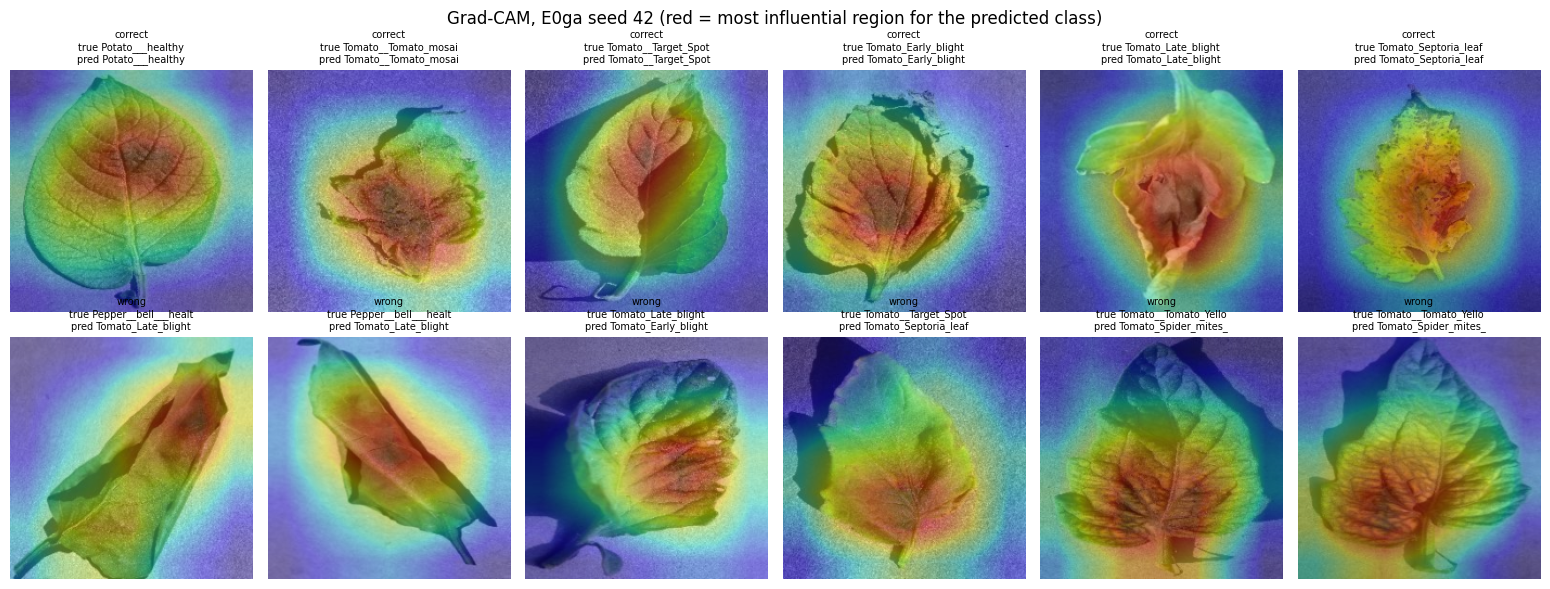

saved /content/drive/MyDrive/Søren og Magnus/Deep Learning /Project_deep/runs/E0ga_gradcam_seed42.png


In [ ]:
# Grad-CAM for one checkpoint (explains the predicted class, saves a PNG to the Drive). Keep.
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from src.dataset import build_dataloaders
from src.models import get_resnet18
from src.trainer import evaluate_full
from src.experiment import DEFAULTS

EXP, SEED = "E0ga", 42  # which checkpoint to explain: checkpoints/<EXP>_seed<SEED>.pt
SHOW_CLASSES = [
    "Potato___healthy",
    "Tomato__Tomato_mosaic_virus",
    "Tomato__Target_Spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Septoria_leaf_spot",
]
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def grad_cam(model, target_layer, x, class_idx=None):
    """Lecturer's Grad-CAM function (Lab 6 template). Returns heatmaps in [0, 1] and the explained class indices."""
    store = {}

    def forward_hook(module, inp, out):
        store["act"] = out
        out.register_hook(lambda grad: store.__setitem__("grad", grad))

    handle = target_layer.register_forward_hook(forward_hook)
    model.eval()
    with torch.enable_grad():
        logits = model(x)
        if class_idx is None:
            class_idx = logits.argmax(1)
        model.zero_grad()
        logits.gather(1, class_idx.view(-1, 1)).sum().backward()
    handle.remove()
    weights = store["grad"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * store["act"]).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    cam = cam / (cam.amax(dim=(2, 3), keepdim=True) + 1e-8)
    return cam.squeeze(1).detach().cpu(), class_idx.cpu()


cfg = {**DEFAULTS, **CONFIG}
_, val_loader, _, class_names = build_dataloaders(
    "/content/data/train", "/content/data/val", "/content/data/test", cfg
)
model = get_resnet18(cfg["num_classes"], freeze_backbone=cfg["freeze_backbone"], dropout=cfg["dropout"]).to(
    device
)
model.load_state_dict(torch.load(f"{PROJECT_ROOT}/checkpoints/{EXP}_seed{SEED}.pt", map_location=device))
model.eval()

res = evaluate_full(model, val_loader, device, class_names=class_names)
preds, targets = np.array(res["preds"]), np.array(res["targets"])
correct = []
for c in SHOW_CLASSES:
    ci = class_names.index(c)
    idx = np.where((targets == ci) & (preds == ci))[0]
    if len(idx):
        correct.append(int(idx[0]))
wrong = [int(i) for i in np.where(preds != targets)[0][:6]]
rows = [("correct", correct), ("wrong", wrong)]
ncol = max(len(correct), len(wrong))

fig, axes = plt.subplots(2, ncol, figsize=(2.6 * ncol, 6))
for r, (label, idxs) in enumerate(rows):
    for col in range(ncol):
        ax = axes[r, col]
        ax.axis("off")
        if col >= len(idxs):
            continue
        i = idxs[col]
        x, y = val_loader.dataset[i]  # image after the eval transform
        cam, cls = grad_cam(model, model.layer4, x.unsqueeze(0).to(device))
        img = (x * STD + MEAN).clamp(0, 1)
        ax.imshow(img.permute(1, 2, 0).numpy())
        ax.imshow(cam[0].numpy(), cmap="jet", alpha=0.4)
        ax.set_title(f"{label}\ntrue {class_names[y][:20]}\npred {class_names[cls.item()][:20]}", fontsize=7)
plt.suptitle(f"Grad-CAM, {EXP} seed {SEED} (red = most influential region for the predicted class)")
plt.tight_layout()
out = f"{PROJECT_ROOT}/runs/{EXP}_gradcam_seed{SEED}.png"
plt.savefig(out, dpi=150)
plt.show()
print("saved", out)

## Fraction splits

In [ ]:
import os, shutil
import numpy as np
from pathlib import Path

SRC = Path("/content/data")
OUT = Path("/content/data_frac")  # derived folders only, splits.json and /content/data are never changed
FRACTIONS = {"f25": 0.25, "f10": 0.10, "f05": 0.05, "f02": 0.02}
SUBSET_SEED = 2026  # fixed: every experiment and every training seed uses the same images
MIN_PER_CLASS = 2

classes = sorted(p.name for p in (SRC / "train").iterdir() if p.is_dir())
assert len(classes) == 15, classes
files = {c: sorted(f for f in os.listdir(SRC / "train" / c)) for c in classes}

rng = np.random.RandomState(SUBSET_SEED)
order = {
    c: rng.permutation(len(files[c])) for c in classes
}  # one permutation per class, so the subsets are nested

# Safety check: no chosen train image may also be in val or test (same class and file name)
held_out = {(c, f) for sp in ("val", "test") for c in classes for f in os.listdir(SRC / sp / c)}

if OUT.exists():
    shutil.rmtree(OUT)

print(
    f'{"fraction":9s} {"train imgs":>10s} {"min class":>10s} {"Potato healthy":>15s} {"Tomato mosaic":>14s}'
)
for tag, frac in FRACTIONS.items():
    total = 0
    counts = {}
    for c in classes:
        k = max(MIN_PER_CLASS, int(round(frac * len(files[c]))))
        chosen = [files[c][i] for i in order[c][:k]]
        assert not any((c, f) in held_out for f in chosen), "overlap with val or test"
        d = OUT / tag / "train" / c
        d.mkdir(parents=True, exist_ok=True)
        for f in chosen:
            os.symlink((SRC / "train" / c / f).resolve(), d / f)
        counts[c] = len(chosen)
        total += len(chosen)
    print(
        f"{tag:9s} {total:>10d} {min(counts.values()):>10d} "
        f'{counts["Potato___healthy"]:>15d} {counts["Tomato__Tomato_mosaic_virus"]:>14d}'
    )

fraction  train imgs  min class  Potato healthy  Tomato mosaic
f25             4116         30              30             72
f10             1646         12              12             29
f05              823          6               6             14
f02              328          2               2              6


In [ ]:
FRAC_RUNS = [("E0f25", "f25"), ("E0f10", "f10"), ("E0f05", "f05"), ("E0f02", "f02")]
for exp_id, tag in FRAC_RUNS:
    n_train = sum(len(os.listdir(OUT / tag / "train" / c)) for c in classes)
    cfg = {**CONFIG, "experiment_id": exp_id, "lr_schedule": "cosine"}
    run_experiment(
        cfg,
        PROJECT_ROOT,
        device,
        eval_test=False,
        notes=f"data fraction {tag}, {n_train} train images",
        train_dir=str(OUT / tag / "train"),
    )

E0f25: seeds already finished: []

--- running E0f25 | seed 0 | code version f0ab6407 ---
Epoch 1/10 | lr 1.00e-04 | train loss 0.6061 | val loss 0.1644 | val acc 0.9505 | val F1 0.9367 | 20.5s
Epoch 2/10 | lr 9.76e-05 | train loss 0.1046 | val loss 0.0809 | val acc 0.9771 | val F1 0.9686 | 21.6s
Epoch 3/10 | lr 9.05e-05 | train loss 0.0480 | val loss 0.0789 | val acc 0.9733 | val F1 0.9649 | 20.9s
Epoch 4/10 | lr 7.94e-05 | train loss 0.0289 | val loss 0.0715 | val acc 0.9738 | val F1 0.9653 | 20.6s
Epoch 5/10 | lr 6.55e-05 | train loss 0.0175 | val loss 0.0750 | val acc 0.9748 | val F1 0.9719 | 20.6s
Epoch 6/10 | lr 5.00e-05 | train loss 0.0120 | val loss 0.0576 | val acc 0.9810 | val F1 0.9767 | 20.7s
Epoch 7/10 | lr 3.45e-05 | train loss 0.0092 | val loss 0.0644 | val acc 0.9795 | val F1 0.9768 | 20.9s
Epoch 8/10 | lr 2.06e-05 | train loss 0.0087 | val loss 0.0582 | val acc 0.9824 | val F1 0.9801 | 20.6s
Epoch 9/10 | lr 9.55e-06 | train loss 0.0060 | val loss 0.0606 | val acc 0.980

In [ ]:
import json, numpy as np

exps = ["E0ga", "E0f25", "E0f10", "E0f05", "E0f02"]
rare = ["Potato___healthy", "Tomato__Tomato_mosaic_virus"]
data = {e: json.load(open(f"{PROJECT_ROOT}/runs/{e}.json")) for e in exps}
classes = data["E0ga"]["classes"]
assert all(data[e]["classes"] == classes for e in exps), "class order differs"
cms = {e: sum(np.array(r["val"]["confusion_matrix"]) for r in data[e]["results"]) for e in exps}

print("Pooled recall over 3 seeds (correct/total in brackets for the rare classes)")
print(f'{"class (val imgs per seed)":48s}' + "".join(f"{e:>9s}" for e in exps))
for i, c in enumerate(classes):
    n = cms["E0ga"][i].sum() // 3
    row = "".join(f"{cms[e][i, i] / cms[e][i].sum():9.3f}" for e in exps)
    print(f'{c + " (" + str(n) + ")":48s}{row}' + ("  <- rare" if c in rare else ""))

print("\nRare classes: correct/total and precision")
for c in rare:
    i = classes.index(c)
    for e in exps:
        cm = cms[e]
        print(
            f"{c:32s} {e:6s} {cm[i, i]:>4d}/{cm[i].sum():<4d} recall {cm[i, i] / cm[i].sum():.3f}  precision {cm[i, i] / max(cm[:, i].sum(), 1):.3f}"
        )

Pooled recall over 3 seeds (correct/total in brackets for the rare classes)
class (val imgs per seed)                            E0ga    E0f25    E0f10    E0f05    E0f02
Pepper__bell___Bacterial_spot (100)                 1.000    0.980    0.983    0.977    0.910
Pepper__bell___healthy (148)                        0.993    0.995    0.998    0.998    0.998
Potato___Early_blight (100)                         1.000    1.000    1.000    0.987    0.967
Potato___Late_blight (100)                          1.000    0.993    0.980    0.893    0.830
Potato___healthy (16)                               0.958    0.917    0.958    0.854    0.229  <- rare
Tomato_Bacterial_spot (215)                         1.000    0.998    0.995    0.991    0.885
Tomato_Early_blight (100)                           0.990    0.957    0.877    0.727    0.527
Tomato_Late_blight (191)                            0.988    0.965    0.953    0.927    0.855
Tomato_Leaf_Mold (96)                               1.000    0.993   

In [ ]:
import shutil
from pathlib import Path

TAG = "f02"  # f10 = 10 percent of train (use f05 for 5 percent later)
FRAC_ROOT = Path(PROJECT_ROOT) / f"frac_{TAG}"
FRAC_ROOT.mkdir(exist_ok=True)
if not (
    FRAC_ROOT / "src"
).exists():  # copy of src/ only so the code version hash is the same as in the main runs
    shutil.copytree(
        Path(PROJECT_ROOT) / "src", FRAC_ROOT / "src", ignore=shutil.ignore_patterns("__pycache__")
    )

for exp_id in ["E1a", "E1b", "E1c"]:
    cfg = {**CONFIG, "experiment_id": exp_id, "lr_schedule": "cosine"}
    run_experiment(
        cfg,
        str(FRAC_ROOT),
        device,
        eval_test=False,
        notes=f"data fraction {TAG}",
        train_dir=str(OUT / TAG / "train"),
    )

## 4. Final test evaluation (run ONLY for chosen models, after all decisions are made on validation data)
Uses the saved checkpoints. Do not run this to compare ideas, and do not pick a model because of its test score.

In [ ]:
# final_test_eval(CONFIG, PROJECT_ROOT, device)   # uncomment when the final models are chosen